In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

In [2]:
# Loading the Datasets (Same two files as Task 2)
df_1 = pd.read_csv("churn-bigml-80.csv")
df_2 = pd.read_csv("churn-bigml-20.csv")
df = pd.concat([df_1, df_2], ignore_index=True)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3333 entries, 0 to 3332
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   State                   3333 non-null   object 
 1   Account length          3333 non-null   int64  
 2   Area code               3333 non-null   int64  
 3   International plan      3333 non-null   object 
 4   Voice mail plan         3333 non-null   object 
 5   Number vmail messages   3333 non-null   int64  
 6   Total day minutes       3333 non-null   float64
 7   Total day calls         3333 non-null   int64  
 8   Total day charge        3333 non-null   float64
 9   Total eve minutes       3333 non-null   float64
 10  Total eve calls         3333 non-null   int64  
 11  Total eve charge        3333 non-null   float64
 12  Total night minutes     3333 non-null   float64
 13  Total night calls       3333 non-null   int64  
 14  Total night charge      3333 non-null   

In [4]:
"""Carrying over the casts from previous task (task 2) so the type of each columns 
is the same Churn rate is 0/1 not True or False, and Area code is a label not a number
"""

df["Churn"] = df["Churn"].astype(int)
df["Area code"] = df["Area code"].astype(str)

print(f"Shape: {df.shape[0]} rows × {df.shape[1]} columns")
print("Churn rate:", round(df["Churn"].mean(), 4))

Shape: 3333 rows × 20 columns
Churn rate: 0.1449


In [5]:
print(df[["Churn", "Area code"]].dtypes)

Churn         int64
Area code    object
dtype: object


### Summary statistics (mean, median, variance)

In [6]:
""" The describe gives us the mean, std, and quartiles but not the variance directly 
so I built a table that has all three side by side
"""

numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns.drop("Churn").tolist()
print("Numeric columns:", numeric_cols)

df[numeric_cols].agg(["mean", "median", "var"]).T.round(2)

Numeric columns: ['Account length', 'Number vmail messages', 'Total day minutes', 'Total day calls', 'Total day charge', 'Total eve minutes', 'Total eve calls', 'Total eve charge', 'Total night minutes', 'Total night calls', 'Total night charge', 'Total intl minutes', 'Total intl calls', 'Total intl charge', 'Customer service calls']


,mean,median,var
Account length,101.06,101.00,1585.80
Number vmail messages,8.10,0.00,187.37
Total day minutes,179.78,179.40,2966.70
Total day calls,100.44,101.00,402.77
Total day charge,30.56,30.50,85.74
Total eve minutes,200.98,201.40,2571.89
Total eve calls,100.11,100.00,396.91
Total eve charge,17.08,17.12,18.58
Total night minutes,200.87,201.20,2557.71
Total night calls,100.11,100.00,382.93


### Split by Target

In [7]:
# Mean of every numeric column split by Churn status
df.groupby("Churn").mean(numeric_only=True).T.round(2)

Churn,0,1
Account length,100.79,102.66
Number vmail messages,8.60,5.12
Total day minutes,175.18,206.91
Total day calls,100.28,101.34
Total day charge,29.78,35.18
Total eve minutes,199.04,212.41
Total eve calls,100.04,100.56
Total eve charge,16.92,18.05
Total night minutes,200.13,205.23
Total night calls,100.06,100.40


### Histograms

##### I picked Total day minutes, Number vmail messages,and customer service calls because those are the three the group showed as most different between churners and non-churners

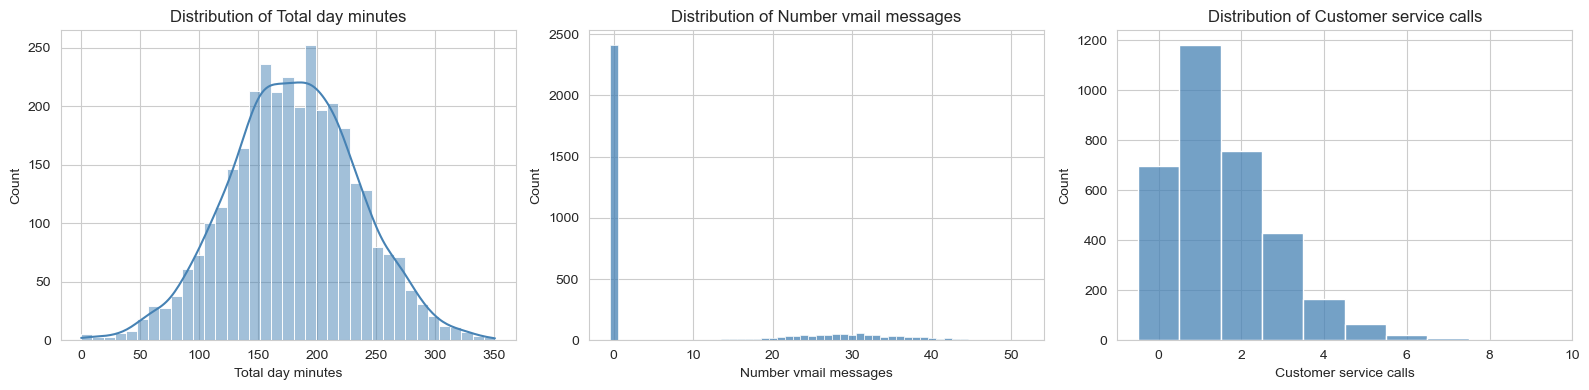

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
hist_specs = [
    ("Total day minutes",      {"kde": True}),
    ("Number vmail messages",  {"kde": False, "discrete": True}),
    ("Customer service calls", {"kde": False, "discrete": True}),
]
for ax, (col, kw) in zip(axes, hist_specs):
    sns.histplot(df[col], ax=ax, color="steelblue", **kw)
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

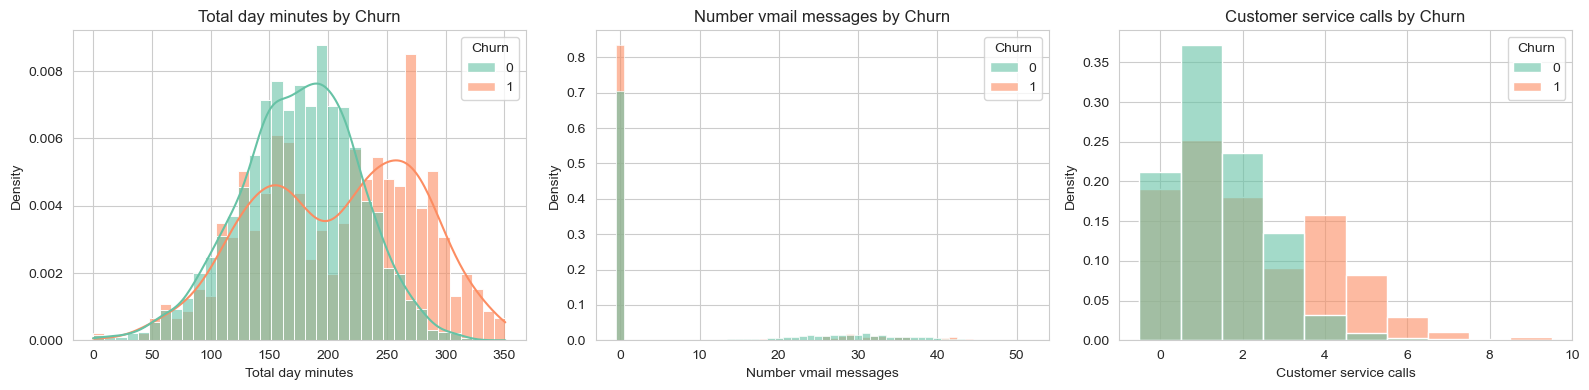

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
hist_specs = [
    ("Total day minutes",      {"kde": True}),
    ("Number vmail messages",  {"kde": False, "discrete": True}),
    ("Customer service calls", {"kde": False, "discrete": True}),
]
for ax, (col, kw) in zip(axes, hist_specs):
    sns.histplot(df, x=col, hue="Churn", multiple="layer", ax=ax,
                 palette="Set2", alpha=0.6, stat="density", common_norm=False, **kw)
    ax.set_title(f"{col} by Churn")
plt.tight_layout()
plt.show()

### Box Plots

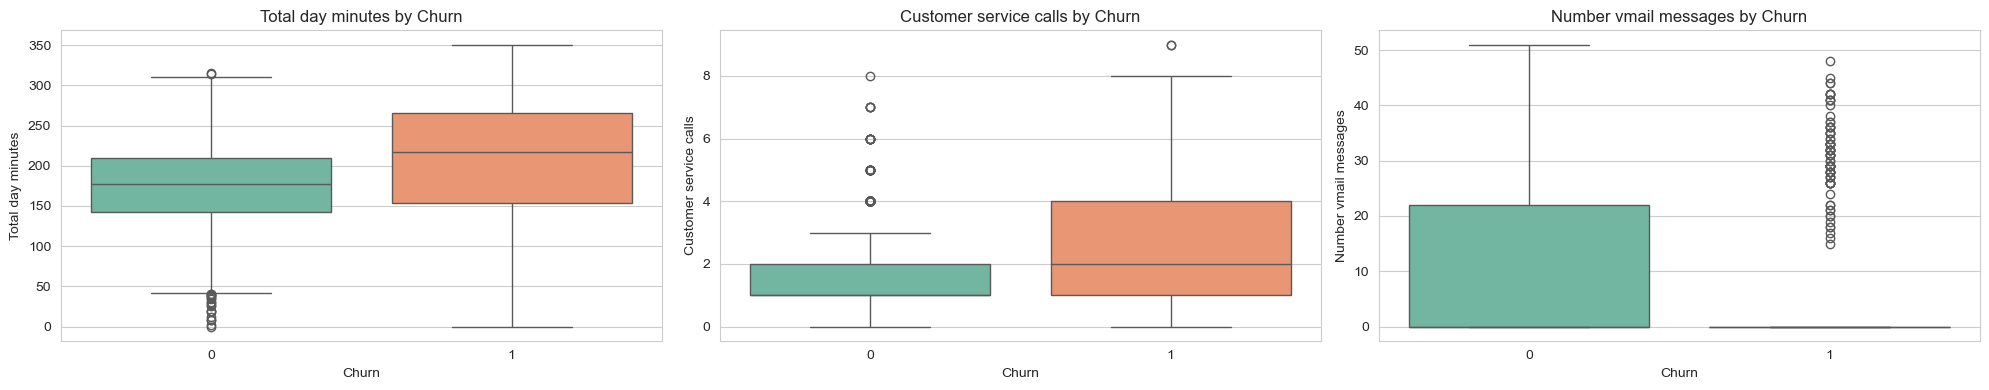

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(20, 4))
for ax, col in zip(axes, ["Total day minutes", "Customer service calls", "Number vmail messages"]):
    sns.boxplot(x="Churn", y=col, data=df, ax=ax, palette="Set2")
    ax.set_title(f"{col} by Churn")
plt.tight_layout()
plt.show()

### Categorical churn rates

##### For categorical columns, averaging means nothing,but churn rate per category is the right summary. groupby(col)["Churn"].mean() gives the fraction of churners within each category.

In [11]:
for col in ["International plan", "Voice mail plan", "Area code"]:
    print(f"\n{col}:")
    print(df.groupby(col)["Churn"].mean().round(3))


International plan:
International plan
No     0.115
Yes    0.424
Name: Churn, dtype: float64

Voice mail plan:
Voice mail plan
No     0.167
Yes    0.087
Name: Churn, dtype: float64

Area code:
Area code
408    0.146
415    0.143
510    0.149
Name: Churn, dtype: float64


In [12]:
print(df.groupby("Customer service calls")["Churn"].agg(["mean", "count"]).round(3))

low = df[df["Customer service calls"] <= 3]["Churn"].mean()
high = df[df["Customer service calls"] >= 4]["Churn"].mean()
print(f"\n0-3 calls: {low:.1%} | 4+ calls: {high:.1%} | ratio: {high/low:.1f}x")

                         mean  count
Customer service calls              
0                       0.132    697
1                       0.103   1181
2                       0.115    759
3                       0.103    429
4                       0.458    166
5                       0.606     66
6                       0.636     22
7                       0.556      9
8                       0.500      2
9                       1.000      2

0-3 calls: 11.3% | 4+ calls: 51.7% | ratio: 4.6x


### Correlation heatmap

In [13]:
# copy so we don't mutate df
df_num = df.copy()

# encode the two Yes/No columns as 0/1, then drop the text columns entirely
df_num["International plan"] = df_num["International plan"].map({"Yes": 1, "No": 0})
df_num["Voice mail plan"]    = df_num["Voice mail plan"].map({"Yes": 1, "No": 0})
df_num["Churn"] = df_num["Churn"].astype(int)

df_num = df_num.select_dtypes(include=["int64", "float64"])


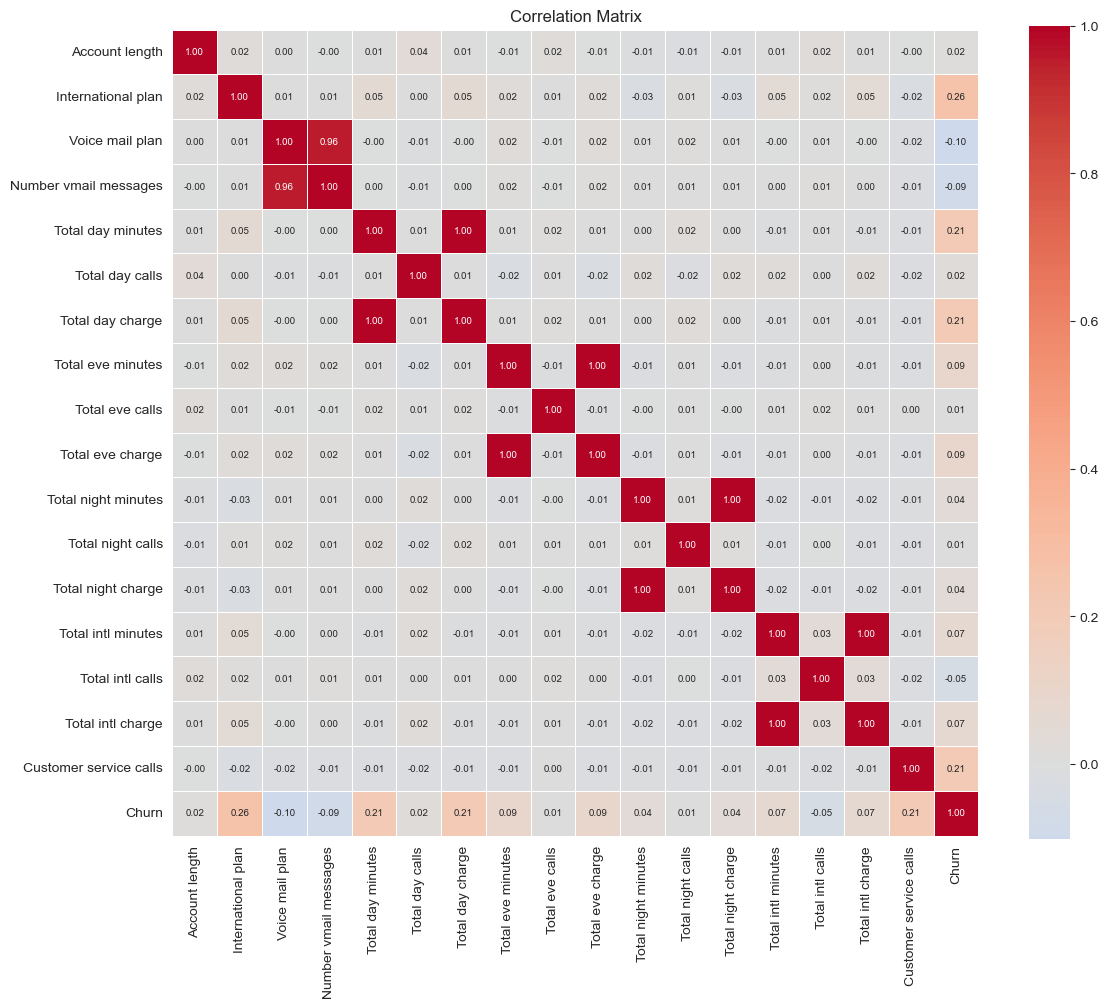

In [14]:
corr = df_num.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5, annot_kws={"size": 7})
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()


### Correlation with Churn rate

In [15]:
# only look at the Churn column of the matrix, drop the self-correlation of 1.0,
# sort by absolute value so the strongest (positive or negative) floats to the top
print(corr["Churn"].drop("Churn").sort_values(key=abs, ascending = False).round(3))

International plan        0.260
Customer service calls    0.209
Total day minutes         0.205
Total day charge          0.205
Voice mail plan          -0.102
Total eve minutes         0.093
Total eve charge          0.093
Number vmail messages    -0.090
Total intl charge         0.068
Total intl minutes        0.068
Total intl calls         -0.053
Total night charge        0.035
Total night minutes       0.035
Total day calls           0.018
Account length            0.017
Total eve calls           0.009
Total night calls         0.006
Name: Churn, dtype: float64


### Minutes to Charge collinearity check

In this dataset, every charge column is literally minutes × rate. If Total day minutes is 180 and the rate is 0.17/min, "Total day charge" is 30.60. So the four (minutes, charge) pairs are not just correlated, they are deterministic linear transforms of each other. Correlations should land at ≈ 0.999.

In [16]:
pairs = [("Total day minutes", "Total day charge"),
         ("Total eve minutes", "Total eve charge"),
         ("Total night minutes", "Total night charge"),
         ("Total intl minutes", "Total intl charge")]
for a, b in pairs:
    print(f"{a} to {b}: r = {corr.loc[a, b]:.4f}")

Total day minutes to Total day charge: r = 1.0000
Total eve minutes to Total eve charge: r = 1.0000
Total night minutes to Total night charge: r = 1.0000
Total intl minutes to Total intl charge: r = 1.0000


### Scatter plot

#### A scatter plot of two highly-correlated features should look like a straight line. If it doesn't, the correlation number is hiding a non-linear relationship. We scatter Total day minutes vs Total day charge coloured by Churn to visually confirm the linear relationship the correlation matrix already reported and see if churners sit anywhere specific along that line.

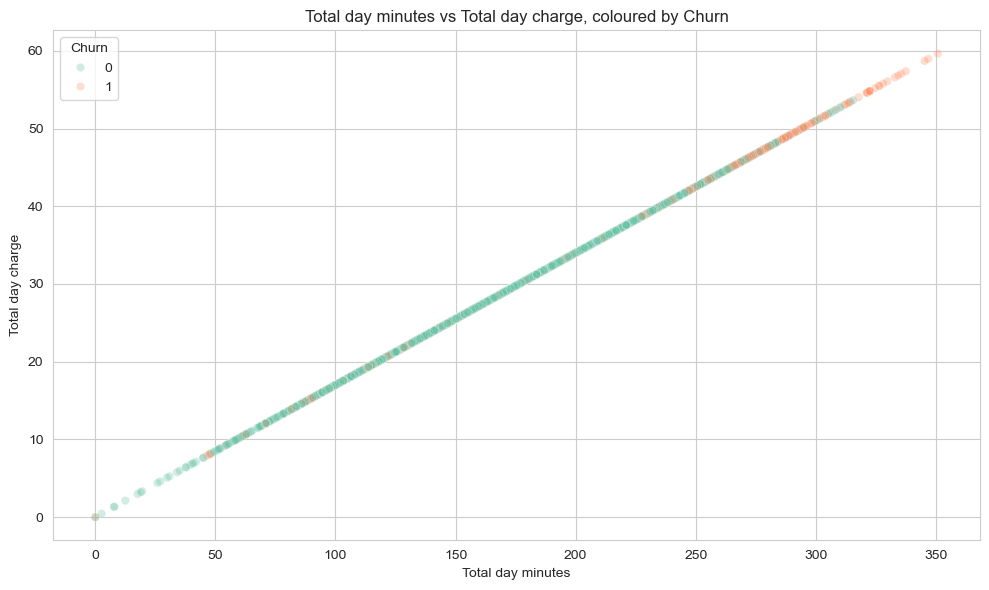

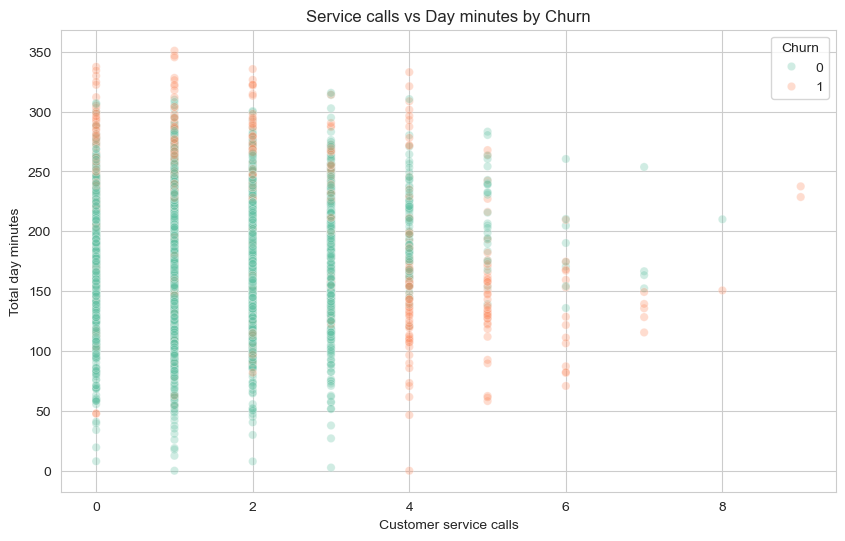

In [17]:
sns.scatterplot(x="Total day minutes", y="Total day charge", data=df,
                hue="Churn", alpha=0.3, palette="Set2")
plt.title("Total day minutes vs Total day charge, coloured by Churn")
plt.tight_layout()
plt.show()

sns.scatterplot(x="Customer service calls", y="Total day minutes", hue="Churn", data=df, alpha = 0.3, palette="Set2")
plt.title("Service calls vs Day minutes by Churn")
plt.show()

### State check

State is a 51-value categorical. We don't plot a 51-bar chart too cluttered and the top of the distribution is all we care about. A value_counts().head(15) shows which states dominate the sample

In [18]:
# state check
print("Top 15 states by customer count:")
print(df["State"].value_counts().head(15))

Top 15 states by customer count:
State
WV    106
MN     84
NY     83
AL     80
OR     78
WI     78
OH     78
WY     77
VA     77
CT     74
MI     73
ID     73
VT     73
UT     72
TX     72
Name: count, dtype: int64


#### Level 1 Task 3 EDA Report: Telecom Churn
1. The Dataset
We're working with 3,333 customers across 20 columns  the combined BigML churn dataset (the 80% and 20% splits merged back together).

Quick sanity checks before anything else:

No missing values, no duplicate rows anywhere in the frame.

Churn is 14.5% — 483 customers left, 2,850 stayed.

2. Summary Statistics
A quick look at the mean, median, and variance for each numeric feature:

Feature	Mean	Median	Variance
Account length	101.06	101.00	1,585.80
Number vmail messages	8.10	0.00	187.37
Total day minutes	179.78	179.40	2,966.70
Total eve minutes	200.98	201.40	2,571.89
Total night minutes	200.87	201.20	2,557.71
Total intl minutes	10.24	10.30	7.79
Customer service calls	1.56	1.00	1.73

Two of these stand out: Number vmail messages and Customer service calls. Their mean is well above their median, and their variance is large relative to the mean. That's the classic shape of a count variable  most customers sit near zero, and a small group accounts for the long tail.

3. Key Findings
1. International Plan is the strongest categorical signal.
Customers on the International Plan churn at 42.4%. Everyone else churns at 11.5%. That's roughly 3.7× the rate.

Its correlation with Churn is 0.26 the highest in the whole dataset.

If you had to pick one feature to build a retention campaign around, it's this one.

2. Customer Service Calls is the strongest behavioural signal.
Churners average 2.23 support calls. Non-churners average 1.45. That's a 54% relative gap — the biggest behavioural difference in the groupby table.

Correlation with Churn is 0.21.

The effect isn't spread evenly, though  it lives in the tail. Customers who make 4 or more calls churn at  51.7% while customers who make 0-3 calls churn at 11.3%  a dramatically higher rate. In retention terms, a fourth call is a red flag worth acting on.

3. Heavy Day Users churn more.
Churners use 206.91 day minutes on average. Non-churners use 175.18.

That's about 18% more day usage among churners. Correlation with Churn: 0.21.

Why might that be? Two plausible stories  heavy users are more price-sensitive because they see bigger bills, or heavy users simply have more surface area for something to go wrong. The data alone can't tell us which. Worth flagging for later, but not something to claim without a targeted test.

4. Voice mail engagement correlates with lower churn.
Customers with a Voice Mail Plan churn at 8.7%. Those without churn at 16.7% — roughly half the rate.

And it's not just the plan itself : usage matters too. Churners average 5.12 voice mail messages. Non-churners average 8.60. That's a 40% drop in engagement among churners.

So both the subscription (categorical) and the usage (count) point in the same direction: voice mail activity goes with retention.

Correlation with Churn: −0.10.

5. Minutes and charge are the same feature  perfectly collinear.
Every (minutes, charge) pair is essentially identical in information:

Total day minutes ↔ Total day charge:1.0

Same for eve, night, and intl pairs.

The reason is trivial once you see it: charge = minutes × rate. A scatter plot of day minutes vs day charge confirms it visually a perfect straight line.

For modelling, keep one of each pair. I'd drop the charge columns and keep the minutes, since minutes are the raw measurement and charge is a derived calculation. Doing this avoids multicollinearity in linear models and stops tree models from wasting splits on information they already have.

6. Several features carry no meaningful signal.
A few features look like they might matter but don't, once you actually measure them:

Account length :  correlation 0.017. Churners average 102.66, non-churners 100.79. That's a gap of less than 2% on a range that runs to 243. Effectively noise.

Area code: churn rates vary between 14.3% and 14.9% across the three codes. Flat.

Total night calls: correlation 0.006. No separation at all.
